In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns


# 1. Load the file
df = pd.read_excel(r"D:\PowerBI_Blank_Table.xlsx.csv.xlsx")

# 2. Check rows & columns
print("Rows and Columns:", df.shape)

# 3. View first 5 rows
df.head()


Rows and Columns: (2560, 15)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,2022-03-12 00:00:00,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,2023-10-08 00:00:00,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,2021-08-07 00:00:00,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90


In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Folder path relative to notebooks/analysis.ipynb
charts_dir = Path("../output/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

In [9]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']


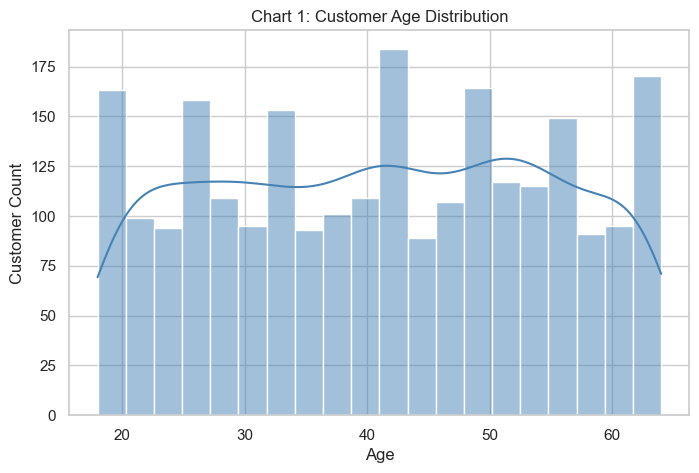

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(df["age"], bins=20, kde=True, color="steelblue")

plt.title("Chart 1: Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Customer Count")

plt.show()

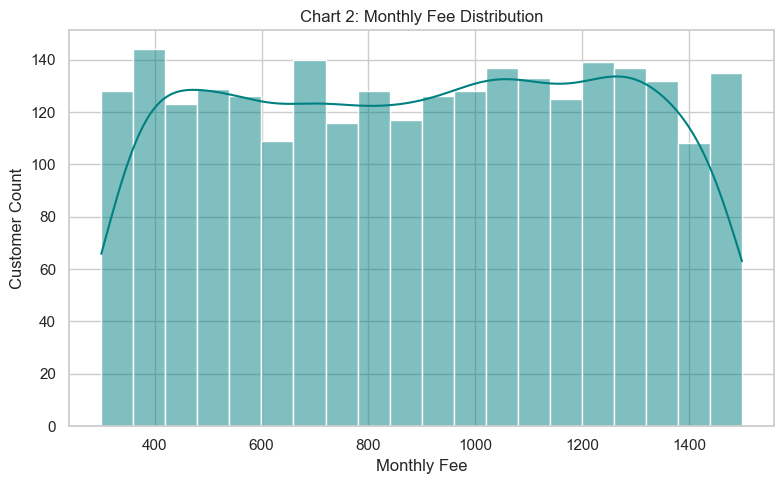

In [11]:
# Chart 2: Monthly Fee Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["monthly_fee"], bins=20, kde=True, color="teal")
plt.title("Chart 2: Monthly Fee Distribution")
plt.xlabel("Monthly Fee")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.savefig(charts_dir / "02_monthly_fee_distribution.png", dpi=150)
plt.show()

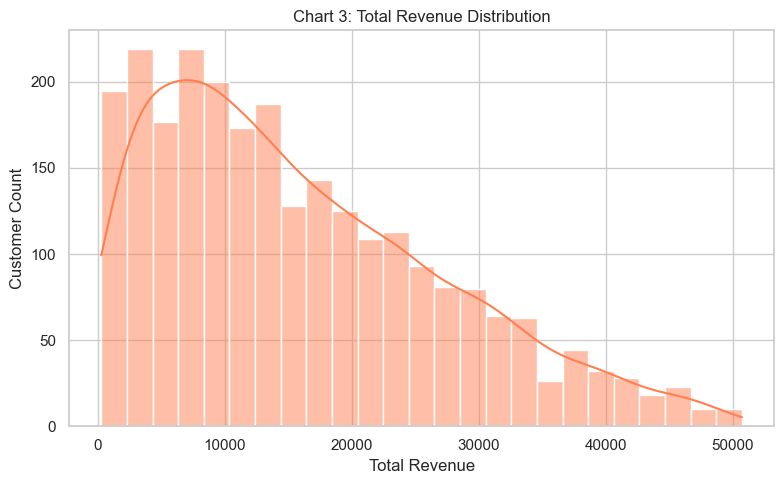

In [12]:
# Chart 3: Total Revenue Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["total_revenue"], bins=25, kde=True, color="coral")
plt.title("Chart 3: Total Revenue Distribution")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.savefig(charts_dir / "03_total_revenue_distribution.png", dpi=150)
plt.show()

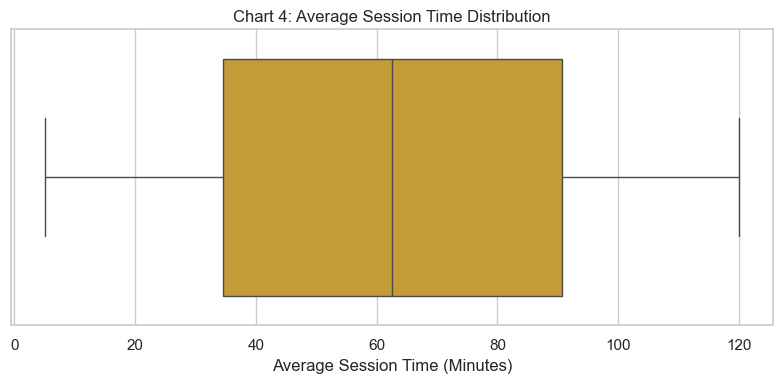

In [13]:
# Chart 4: Average Session Time Boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["avg_session_time"], color="goldenrod")
plt.title("Chart 4: Average Session Time Distribution")
plt.xlabel("Average Session Time (Minutes)")
plt.tight_layout()
plt.savefig(charts_dir / "04_session_time_boxplot.png", dpi=150)
plt.show()

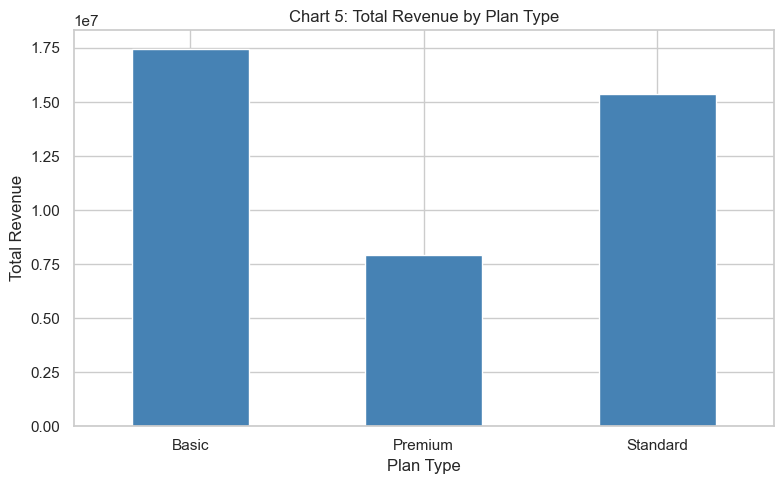

In [14]:
# Chart 5: Total Revenue by Plan Type
plt.figure(figsize=(8, 5))
df.groupby("plan_type")["total_revenue"].sum().plot(kind="bar", color="steelblue", rot=0)
plt.title("Chart 5: Total Revenue by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.savefig(charts_dir / "05_revenue_by_plan.png", dpi=150)
plt.show()

In [16]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']


In [17]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

print(df.columns.tolist())

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']


In [18]:
if "churn_flag" in df.columns:
    print("churn_flag column found")
else:
    print("churn_flag column is missing")

churn_flag column is missing


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Check required columns
print(df.columns.tolist())

if "plan_type" in df.columns and "churn_flag" in df.columns:

    plt.figure(figsize=(8, 5))

    churn_rate = df.groupby("plan_type")["churn_flag"].mean() * 100

    churn_rate.plot(kind="bar", color="indianred", rot=0)

    plt.title("Chart 6: Churn Rate (%) by Plan Type")
    plt.xlabel("Plan Type")
    plt.ylabel("Churn Rate (%)")
    plt.tight_layout()
    plt.show()

else:
    print("Required column is missing. Check your Excel column names.")

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']
Required column is missing. Check your Excel column names.


In [21]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']


In [25]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']


In [29]:
df["churned"] = df["churned"].map({"Yes": 1, "No": 0})

In [30]:
df["churned"].value_counts()

churned
0    1957
1     603
Name: count, dtype: int64

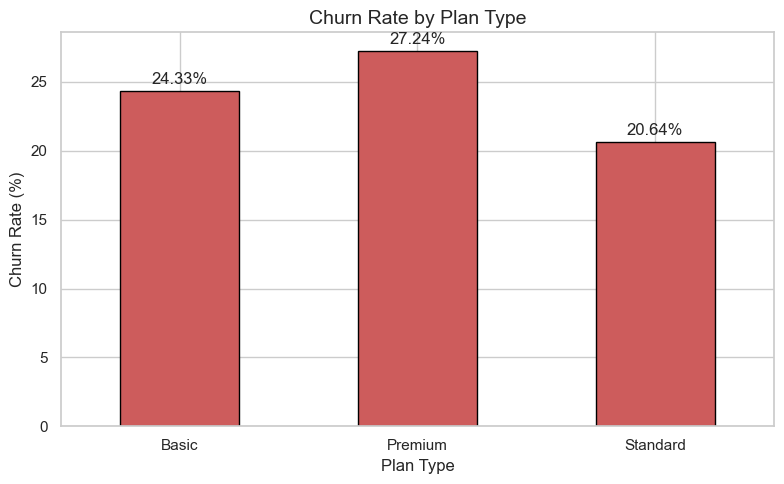

In [31]:
import matplotlib.pyplot as plt

# Calculate churn rate by plan type
churn_rate = df.groupby("plan_type")["churned"].mean() * 100

# Create bar chart
plt.figure(figsize=(8, 5))

churn_rate.plot(
    kind="bar",
    color="indianred",
    edgecolor="black",
    rot=0
)

# Add labels and title
plt.title("Churn Rate by Plan Type", fontsize=14)
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate (%)")

# Display percentage values
for i, value in enumerate(churn_rate):
    plt.text(i, value + 0.5, f"{value:.2f}%",
             ha="center")

plt.tight_layout()
plt.show()

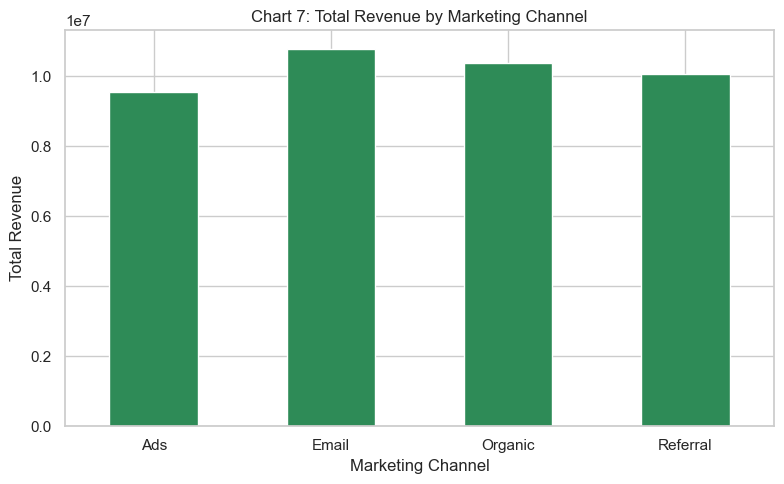

In [35]:
# Chart 7: Total Revenue by Marketing Channel
plt.figure(figsize=(8, 5))
df.groupby("marketing_channel")["total_revenue"].sum().plot(kind="bar", color="seagreen", rot=0)
plt.title("Chart 7: Total Revenue by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.savefig(charts_dir / "07_revenue_by_channel.png", dpi=150)
plt.show()

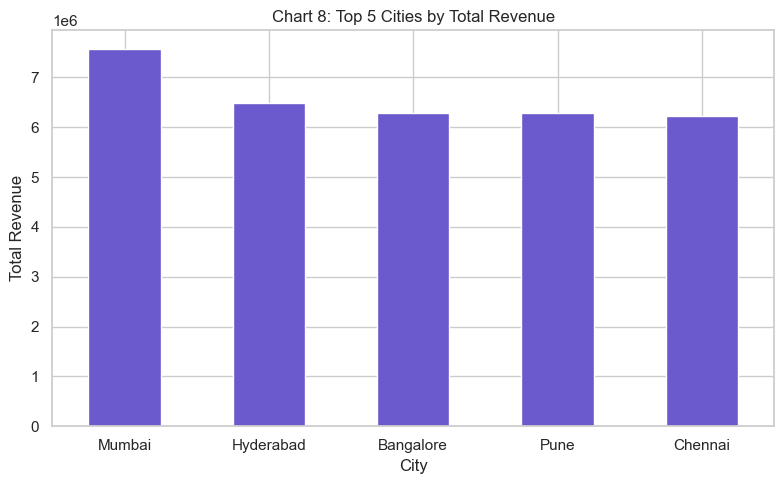

In [36]:
# Chart 8: Top 5 Cities by Total Revenue
plt.figure(figsize=(8, 5))
df.groupby("city")["total_revenue"].sum().nlargest(5).plot(kind="bar", color="slateblue", rot=0)
plt.title("Chart 8: Top 5 Cities by Total Revenue")
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.savefig(charts_dir / "08_top_5_cities_revenue.png", dpi=150)
plt.show()

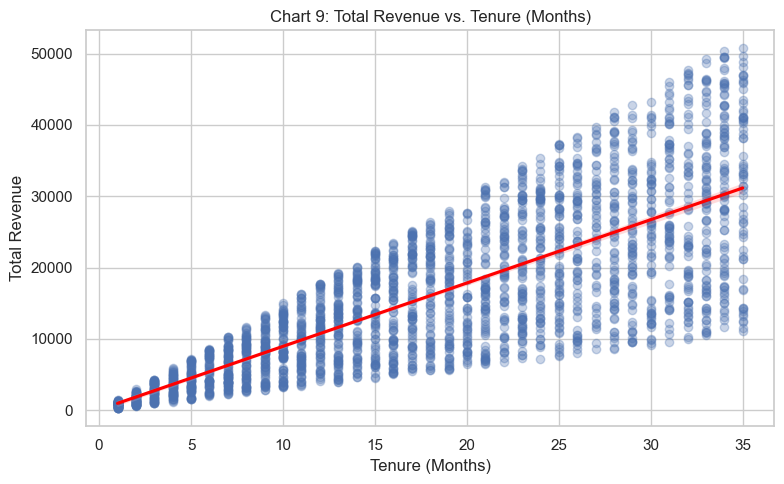

In [38]:
# Chart 9: Total Revenue vs Tenure (Regression Plot)
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="tenure_months", y="total_revenue", scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Chart 9: Total Revenue vs. Tenure (Months)")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.savefig(charts_dir / "09_revenue_vs_tenure.png", dpi=150)
plt.show()



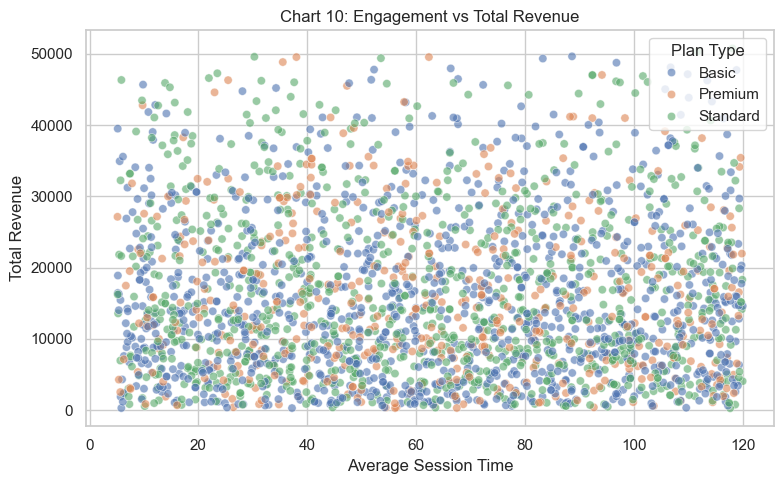

In [40]:
# Chart 10: Engagement vs Total Revenue (Scatter Plot)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="avg_session_time",
    y="total_revenue",
    hue="plan_type",
    alpha=0.6
)

plt.title("Chart 10: Engagement vs Total Revenue")
plt.xlabel("Average Session Time")
plt.ylabel("Total Revenue")
plt.legend(title="Plan Type")
plt.tight_layout()
plt.show()

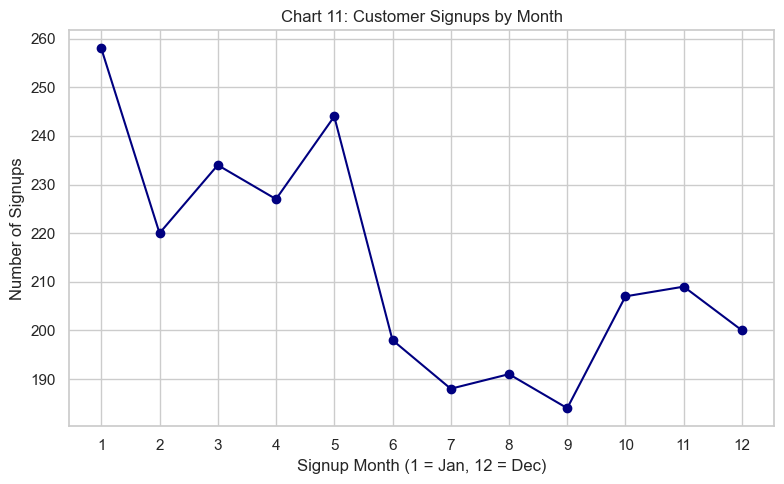

In [42]:
# Chart 11: Monthly Signups Trend

import pandas as pd
import matplotlib.pyplot as plt

# Convert signup_date into datetime
df["signup_date"] = pd.to_datetime(df["signup_date"])

# Extract month from signup_date
df["signup_month"] = df["signup_date"].dt.month

# Group by month and count customers
monthly_signups = df.groupby("signup_month")["customer_id"].count()

# Create line chart
plt.figure(figsize=(8, 5))

monthly_signups.plot(
    kind="line",
    marker="o",
    color="navy"
)

plt.title("Chart 11: Customer Signups by Month")
plt.xlabel("Signup Month (1 = Jan, 12 = Dec)")
plt.ylabel("Number of Signups")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

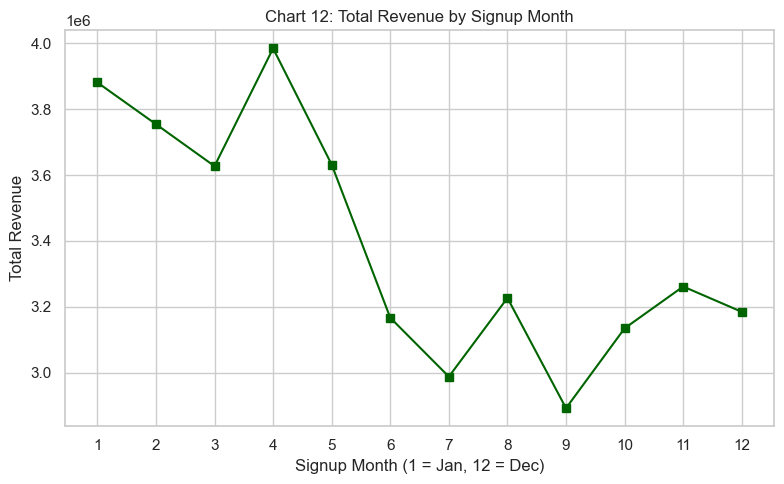

In [43]:
# Chart 12: Monthly Revenue Trend
plt.figure(figsize=(8, 5))
df.groupby("signup_month")["total_revenue"].sum().plot(kind="line", marker="s", color="darkgreen")
plt.title("Chart 12: Total Revenue by Signup Month")
plt.xlabel("Signup Month (1 = Jan, 12 = Dec)")
plt.ylabel("Total Revenue")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig(charts_dir / "12_revenue_by_month.png", dpi=150)
plt.show()

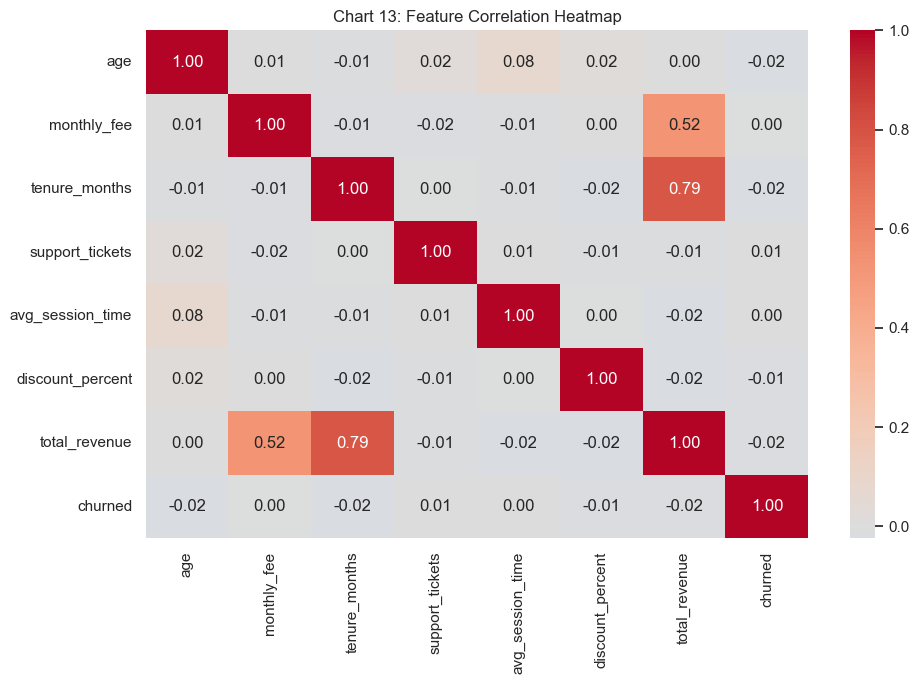

In [45]:
# Chart 13: Feature Correlation Heatmap

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select existing numerical columns
num_cols = [
    "age",
    "monthly_fee",
    "tenure_months",
    "support_tickets",
    "avg_session_time",
    "discount_percent",
    "total_revenue",
    "churned"
]

# Convert columns to numeric if required
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Chart 13: Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

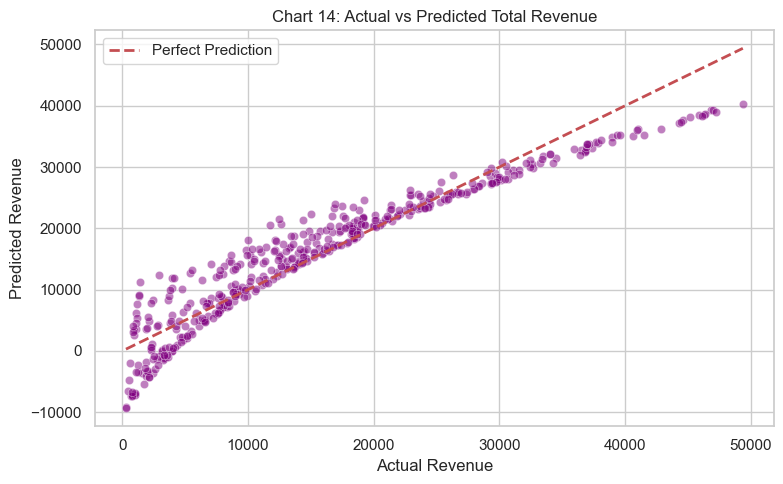

Mean Absolute Error: 2739.714606211725
R2 Score: 0.8996613404260918


In [48]:

# Chart 14: Actual vs Predicted Revenue

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Step 1: Select input features
features = [
    "age",
    "monthly_fee",
    "tenure_months",
    "support_tickets",
    "avg_session_time",
    "discount_percent"
]

# Step 2: Prepare data
X = df[features]
y = df["total_revenue"]

data = pd.concat([X, y], axis=1).dropna()

X = data[features]
y = data["total_revenue"]

# Step 3: Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Step 4: Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Predict revenue
y_pred = model.predict(X_test)

# Step 6: Create scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5,
    color="purple"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Perfect Prediction"
)

plt.title("Chart 14: Actual vs Predicted Total Revenue")
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.legend()
plt.tight_layout()
plt.show()

# Step 7: Model performance
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))


In [50]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue', 'signup_month']


In [51]:

import pandas as pd

# Step 1: Create plan_rank
print("Available Plans:", df['plan_type'].unique())

df['plan_rank'] = (
    df['plan_type'].astype(str).str.strip().str.lower()
    .map({
        'basic': 1,
        'standard': 2,
        'premium': 3
    })
)

# Step 2: Create engagement_score
df['engagement_score'] = (
    df['avg_session_time'] * 0.5 +
    df['tenure_months'] * 0.3 -
    df['support_tickets'] * 0.2
)

# Step 3: Create churn_flag
df['churn_flag'] = df['churned'].astype(int)

# Step 4: Define numerical features
num_features = [
    'age',
    'monthly_fee',
    'tenure_months',
    'support_tickets',
    'avg_session_time',
    'discount_percent',
    'total_revenue',
    'plan_rank',
    'engagement_score'
]

# Step 5: Check missing plan ranks
print("Missing plan_rank:", df['plan_rank'].isnull().sum())

# Step 6: Prepare features
X = pd.get_dummies(
    df[num_features + ['gender', 'marketing_channel']],
    columns=['gender', 'marketing_channel'],
    drop_first=True,
    dtype=int
)

# Step 7: Target variable
y = df['churn_flag']

# Step 8: Display results
print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Data:")
display(X.head())

print("\nTarget Data:")
display(y.head())


Available Plans: ['Basic' 'Premium' 'Standard']
Missing plan_rank: 0

Feature Shape: (2560, 14)
Target Shape: (2560,)

Feature Data:


,age,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,total_revenue,plan_rank,engagement_score,gender_Male,gender_Other,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Referral
0,56.0,1214,25,5,15.75,15.0,30167.90,1,14.375,0,0,0,0,1
1,46.0,1268,22,1,37.16,20.0,27642.40,3,24.980,0,0,0,1,0
2,32.0,783,4,0,41.93,5.0,3092.85,1,22.165,0,0,0,0,1
3,60.0,545,4,1,116.41,0.0,2180.00,2,59.205,1,0,0,1,0
4,25.0,1331,30,1,81.89,10.0,39796.90,1,49.745,0,0,0,0,0



Target Data:


0    1
1    1
2    0
3    0
4    0
Name: churn_flag, dtype: int64

In [52]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select approved numeric features
num_features = [
    "age", "monthly_fee", "tenure_months", "support_tickets",
    "avg_session_time", "discount_percent", "plan_rank",
    "engagement_score", "churn_flag"
]

# 2. One-hot encode categorical columns ('gender' and 'marketing_channel') into 0/1 columns
X = pd.get_dummies(
    df[num_features + ["gender", "marketing_channel"]],
    columns=["gender", "marketing_channel"],
    drop_first=True,
    dtype=int
)

# 3. Define target variable
y = df["total_revenue"]

print("Feature matrix shape (X):", X.shape)
print("Features used:", list(X.columns))

Feature matrix shape (X): (2560, 14)
Features used: ['age', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'plan_rank', 'engagement_score', 'churn_flag', 'gender_Male', 'gender_Other', 'marketing_channel_Email', 'marketing_channel_Organic', 'marketing_channel_Referral']


In [57]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer

# Replace missing values (NaN) with column mean
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(X)

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
pred = model.predict(X_test)

print(f"Training rows: {X_train.shape[0]} | Testing rows: {X_test.shape[0]}")


Training rows: 2048 | Testing rows: 512


In [58]:

# Import evaluation metrics
import numpy as np
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Predict total revenue
pred = model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)

# Display results
print("Revenue Forecasting Model Evaluation")
print("------------------------------------")

print(f"R² Score : {r2:.4f} ({r2*100:.2f}% of revenue variance explained)")
print(f"MAE      : {mae:,.2f}")
print(f"MSE      : {mse:,.2f}")
print(f"RMSE     : {rmse:,.2f}")


Revenue Forecasting Model Evaluation
------------------------------------
R² Score : -0.0009 (-0.09% of revenue variance explained)
MAE      : 0.36
MSE      : 0.18
RMSE     : 0.43


In [62]:
feature_names = df.drop(columns=['total_revenue']).columns

In [64]:

from pathlib import Path
import pandas as pd
import numpy as np

# Create output folder
output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

# Get feature names
if hasattr(X, "columns"):
    feature_names = X.columns
else:
    feature_names = [f"Feature_{i}" for i in range(X.shape[1])]

# Get Linear Regression coefficients
coefficients = np.array(model.coef_).flatten()

# Create DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient
coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

# Display results
print("Revenue Forecasting - Feature Coefficients")
display(coef_df)

# Save CSV file
coef_df.to_csv(
    output_dir / "feature_coefficients.csv",
    index=False
)

print("Feature coefficients saved successfully!")


Revenue Forecasting - Feature Coefficients


,Feature,Coefficient,Absolute_Coefficient
11,Feature_11,2.558049e-02,2.558049e-02
8,Feature_8,1.529015e-02,1.529015e-02
9,Feature_9,1.321803e-02,1.321803e-02
10,Feature_10,-1.184548e-02,1.184548e-02
12,Feature_12,1.072898e-02,1.072898e-02
4,Feature_4,-7.534909e-03,7.534909e-03
7,Feature_7,7.347256e-03,7.347256e-03
13,Feature_13,5.576461e-03,5.576461e-03
2,Feature_2,-3.578972e-03,3.578972e-03
3,Feature_3,3.506261e-03,3.506261e-03


Feature coefficients saved successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Load dataset
df = pd.read_excel(r"D:\PowerBI_Blank_Table.xlsx.csv.xlsx")

# ---------------------------------------------------------
# A. CORRELATION HEATMAP & MODEL COEFFICIENTS (Question 1)
# ---------------------------------------------------------
# Encode categorical variables (e.g., plan, discount_category)


# Correlation Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Train-Test Split & Linear Regression
X = df_encoded.drop(columns=['revenue'])
y = df_encoded['revenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Display sorted model coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("=== MODEL COEFFICIENTS ===")
print(coef_df.to_string(index=False))

# ---------------------------------------------------------
# B. TENURE, PLAN, DISCOUNTS & USAGE (Question 2)
# ---------------------------------------------------------
# Discount Category Summary Table
discount_table = df.groupby('discount_category')['revenue'].agg(
    Count='count',
    Mean_Revenue='mean',
    Median_Revenue='median'
).round(2)
print("\n=== DISCOUNT CATEGORY TABLE ===")
print(discount_table)

# Charts 5, 9, 10: Tenure, Plan, and Usage vs. Revenue
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.regplot(data=df, x='tenure', y='revenue', ax=axes[0], scatter_kws={'alpha':0.4})
axes[0].set_title("Chart 5: Tenure vs Revenue")

sns.barplot(data=df, x='plan', y='revenue', ax=axes[1], estimator=np.mean)
axes[1].set_title("Chart 9: Average Revenue by Plan")

sns.regplot(data=df, x='usage', y='revenue', ax=axes[2], scatter_kws={'alpha':0.4})
axes[2].set_title("Chart 10: Usage vs Revenue")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# C. SEGMENT VALUE & HIGH-VALUE SHARE (Question 3)
# ---------------------------------------------------------
# Create age groups if not already present
if 'age_group' not in df.columns:
    df['age_group'] = pd.cut(df['age'], bins=[17, 25, 35, 50, 100], labels=['18-25', '26-35', '36-50', '51+'])

# Define High-Value Customers (e.g., top 25% of revenue)
hv_threshold = df['revenue'].quantile(0.75)
df['is_high_value'] = df['revenue'] >= hv_threshold

segment_table = df.groupby(['age_group', 'plan'], observed=False).agg(
    Avg_Revenue=('revenue', 'mean'),
    High_Value_Share_Pct=('is_high_value', lambda x: x.mean() * 100)
).round(2)

print(f"\n=== SEGMENT VALUE (High-Value Threshold: ${hv_threshold:.2f}) ===")
print(segment_table)

# ---------------------------------------------------------
# D. MODEL RELIABILITY: R², MAE & ACTUAL VS PREDICTED (Question 4)
# ---------------------------------------------------------
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f"\n=== MODEL PERFORMANCE ===\nR²: {r2:.4f}\nMAE: ${mae:.2f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Revenue ($)")
plt.ylabel("Predicted Revenue ($)")
plt.title(f"Actual vs. Predicted Revenue (R² = {r2:.2f}, MAE = ${mae:.2f})")
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

sns.set_style("whitegrid")

# Check dataset
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (2560, 15)

Columns:
['customer_id', 'age', 'gender', 'city', 'signup_date', 'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months', 'support_tickets', 'avg_session_time', 'discount_percent', 'marketing_channel', 'churned', 'total_revenue']

First 5 Rows:


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,2022-03-12 00:00:00,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,2023-10-08 00:00:00,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,2021-08-07 00:00:00,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90


In [7]:
print("DataFrames:", [k for k, v in locals().items() if hasattr(v, 'columns')])
print("Models:", [k for k, v in locals().items() if hasattr(v, 'coef_') or hasattr(v, 'named_steps')])

DataFrames: ['df', 'df_encoded']
Models: []


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Automatically find your existing DataFrame in memory (no CSV filename needed)
dfs = [v for k, v in locals().items() if isinstance(v, pd.DataFrame) and not k.startswith('_')]
if not dfs:
    raise ValueError("No DataFrame found! Run the earlier cell that loads your CSV first.")
df_work = dfs[0].copy()

# 2. Find the revenue column automatically (case-insensitive)
rev_cols = [c for c in df_work.columns if 'rev' in c.lower()]
target_col = rev_cols[0] if rev_cols else df_work.columns[-1]

# 3. Drop ID/date columns if present and encode text columns
drop_cols = [c for c in df_work.columns if 'id' in c.lower() or 'date' in c.lower()]
df_encoded = pd.get_dummies(df_work.drop(columns=drop_cols), drop_first=True).dropna()

# 4. Define X and y, split, and train the model
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Print model coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", key=abs, ascending=False)

print(f"Target column used: {target_col}\n")
print(coefficients.to_string(index=False))

Target column used: total_revenue

                   Feature  Coefficient
             tenure_months   894.548642
              gender_Other   673.431526
            city_Hyderabad   281.391348
 marketing_channel_Organic   199.299241
                city_Delhi  -186.293749
              city_Chennai   158.730619
               gender_Male   109.571241
         plan_type_Premium   -97.944066
               churned_Yes   -97.534760
               city_Mumbai   -77.614884
marketing_channel_Referral    62.503904
           support_tickets    48.936447
                 city_Pune    36.018777
   marketing_channel_Email   -32.867301
               monthly_fee    17.848297
          discount_percent   -11.357851
                       age     7.460508
        plan_type_Standard    -4.510263
          avg_session_time    -0.512440


In [9]:
df["discount_category"] = pd.cut(
    df["discount_percent"],
    bins=[-1, 10, 20, 30, 50, 100],
    labels=["0-10%", "11-20%", "21-30%", "31-50%", "Above 50%"]
)

discount_analysis = df.groupby(
    "discount_category", observed=False
).agg(
    Average_Revenue=("total_revenue", "mean"),
    Customer_Count=("customer_id", "count")
)

print(discount_analysis)

                   Average_Revenue  Customer_Count
discount_category                                 
0-10%                 16366.694912            1474
11-20%                15183.596177             981
21-30%                         NaN               0
31-50%                         NaN               0
Above 50%                      NaN               0


In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Auto-detect your active DataFrame
dfs = [v for k, v in locals().items() if isinstance(v, pd.DataFrame) and not k.startswith('_')]
df_work = dfs[0].copy()

# Helper to find columns by keyword
def find_col(keywords):
    for kw in keywords:
        matches = [c for c in df_work.columns if kw in c.lower()]
        if matches:
            return matches[0]
    return None

rev_col = find_col(['rev'])
tenure_col = find_col(['tenure', 'month'])
plan_col = find_col(['plan', 'tier'])
disc_col = find_col(['discount'])
usage_col = find_col(['usage'])
age_col = find_col(['age'])

# 2. Train Model & Extract Coefficients, R², MAE (Questions 1 & 4)
drop_cols = [c for c in df_work.columns if 'id' in c.lower() or 'date' in c.lower()]
df_encoded = pd.get_dummies(df_work.drop(columns=drop_cols), drop_first=True).dropna()

X = df_encoded.drop(columns=[rev_col])
y = df_encoded[rev_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

coefs = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_}).sort_values(by='Coefficient', key=abs, ascending=False)
corrs = df_encoded.corr()[rev_col].drop(rev_col).sort_values(key=abs, ascending=False)

print("=== Q1: TOP COEFFICIENTS & CORRELATIONS ===")
print("Top 3 Coefficients:\n", coefs.head(3).to_string(index=False))
print("\nTop 3 Heatmap Correlations with Revenue:\n", corrs.head(3).round(2).to_string())

print("\n=== Q2: TENURE, PLAN, DISCOUNTS & USAGE ===")
if tenure_col and pd.api.types.is_numeric_dtype(df_work[tenure_col]):
    print(f"Tenure correlation (Chart 5): r = {df_work[tenure_col].corr(df_work[rev_col]):.2f}")
if usage_col and pd.api.types.is_numeric_dtype(df_work[usage_col]):
    print(f"Usage correlation (Chart 10): r = {df_work[usage_col].corr(df_work[rev_col]):.2f}")
if plan_col:
    print("\nMean Revenue by Plan (Chart 9):\n", df_work.groupby(plan_col, observed=False)[rev_col].mean().round(2).to_string())
if disc_col:
    print("\nMean Revenue by Discount:\n", df_work.groupby(disc_col, observed=False)[rev_col].mean().round(2).to_string())

print("\n=== Q3: SEGMENT VALUE & HIGH-VALUE SHARE ===")
if age_col and plan_col:
    age_grp = df_work[age_col] if not pd.api.types.is_numeric_dtype(df_work[age_col]) else pd.cut(df_work[age_col], bins=[17, 25, 35, 50, 100], labels=['18-25', '26-35', '36-50', '51+'])
    hv_cut = df_work[rev_col].quantile(0.75)
    df_work['high_value'] = (df_work[rev_col] >= hv_cut) * 100
    seg = df_work.groupby([age_grp, plan_col], observed=False).agg(
        Avg_Rev=(rev_col, 'mean'),
        HV_Share_Pct=('high_value', 'mean')
    ).round(2)
    print(seg.to_string())

print("\n=== Q4: MODEL ACCURACY ===")
print(f"R² Score: {r2_score(y_test, y_pred):.3f}")
print(f"MAE: ${mean_absolute_error(y_test, y_pred):.2f}")

=== Q1: TOP COEFFICIENTS & CORRELATIONS ===
Top 3 Coefficients:
                  Feature  Coefficient
           tenure_months   893.835598
            gender_Other   650.294235
discount_category_11-20%  -639.468307

Top 3 Heatmap Correlations with Revenue:
 tenure_months               0.79
monthly_fee                 0.52
discount_category_11-20%   -0.05

=== Q2: TENURE, PLAN, DISCOUNTS & USAGE ===
Tenure correlation (Chart 5): r = 0.79

Mean Revenue by Plan (Chart 9):
 plan_type
Basic       15544.77
Premium     15713.91
Standard    16459.87

Mean Revenue by Discount:
 discount_percent
0.0     15912.16
5.0     16018.62
10.0    17165.34
15.0    14841.04
20.0    15509.13

=== Q3: SEGMENT VALUE & HIGH-VALUE SHARE ===
                  Avg_Rev  HV_Share_Pct
age   plan_type                        
18-25 Basic      15936.31         27.17
      Premium    14802.39         18.06
      Standard   15586.40         20.99
26-35 Basic      16601.87         25.97
      Premium    15328.21         